# Airbnb Strategy Lab · Modélisation

**Objectif :** prédire le prix d'une nuit à partir des caractéristiques du logement, puis repérer les logements sous-évalués.

**Apprentissage supervisé :** le modèle apprend à partir d'exemples dont on connaît le prix.
- **Features (X)** : les caractéristiques du logement (quartier, type, avis…)
- **Target (y)** : le prix (`price`)

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/AB_NYC_2019_clean.csv")
df.shape

(47692, 18)

## 1. Choix des variables

**Features retenues :** `neighbourhood_group`, `room_type`, `latitude`, `longitude`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`, `availability_365`.

**Variables exclues :**
- `ìd`, `name`, `host_id`, `host_name`: des identifiants, sans lien logique avec le prix. 
- `last_review`: une date, avec 20% de valeurs manquantes. 
- ` neighbourhood`: 221 quartiers différents, trop détaillé. On garde l'arrondissement et les coordonnées GPS, qui portent déjà la localisation. 

**Fuites de données (data leakage) :**
- `revenu_estime`est calculé **à partir du prix** (prix x avis par mois). 
- `categorie_prix`est calculée **à parir du prix** (découpage en 3 groupes). 

les utilser reviendrait à **donner la réponse au modèle** : il obtiendrait un score excellent mais totalement artificiel, et serait inutilisable sur un nouveau logemen dont on ne connait pas le prix. On les exclut donc. 

In [89]:
features = ["neighbourhood_group", "room_type", "latitude", "longitude",
            "minimum_nights", "number_of_reviews", "reviews_per_month",
            "calculated_host_listings_count", "availability_365"]

X = df[features]
y = df["price"]

print("X :", X.shape)
print("y :", y.shape)

X : (47692, 9)
y : (47692,)


## 2. Encodage des variables catégorielles
Un modèle ne comprend que les **nombres**. On transforme les colonnes texte (`neighbourhood_group`, `room_type`) avec `get_dummies` : chaque catégorie devient une colonne qui vaut 1 (oui) ou 0 (non).

In [90]:
X = pd.get_dummies(X, columns=["neighbourhood_group", "room_type"])
X.head()

,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,1,9,0.21,6,365,False,True,False,False,False,False,True,False
1,40.75362,-73.98377,1,45,0.38,2,355,False,False,True,False,False,True,False,False
2,40.80902,-73.94190,3,0,0.00,1,365,False,False,True,False,False,False,True,False
3,40.68514,-73.95976,1,270,4.64,1,194,False,True,False,False,False,True,False,False
4,40.79851,-73.94399,10,9,0.10,1,0,False,False,True,False,False,True,False,False


## 3. Découpage entraînement / test
- **80 %** des données servent à entraîner le modèle.
- **20 %** sont mises de côté pour l'évaluer sur des logements qu'il n'a jamais vus.

`random_state=42` fixe le hasard du découpage, pour obtenir les mêmes résultats à chaque exécution.

In [91]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (38153, 15)
Test : (9539, 15)


## 4. Baseline : régression linéaire

La régression linéaire est le modèle le plus simple : elle cherche une formule du type *prix = a + b × feature1 + c × feature2 + …*. Elle sert de **point de référence** à battre.

**Métriques d'évaluation (sur le jeu de test) :**
- **MAE** : l'erreur moyenne en dollars.
- **RMSE** : l'erreur moyenne qui pénalise davantage les grosses erreurs.
- **R²** : la part de la variation des prix expliquée par le modèle (de 0 à 1).

In [92]:
modele_lr = LinearRegression()
modele_lr.fit(X_train, y_train)

pred_lr = modele_lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
r2_lr = r2_score(y_test, pred_lr)

print("MAE  :", round(mae_lr, 2), "$")
print("RMSE :", round(rmse_lr, 2), "$")
print("R²   :", round(r2_lr, 3))

MAE  : 52.76 $
RMSE : 83.91 $
R²   : 0.363


In [93]:
coefficients = pd.Series(modele_lr.coef_, index=X.columns)
coefficients.round(2)

latitude                            -107.29
longitude                           -379.26
minimum_nights                        -1.51
number_of_reviews                     -0.16
reviews_per_month                     -1.58
calculated_host_listings_count         0.14
availability_365                       0.14
neighbourhood_group_Bronx             20.49
neighbourhood_group_Brooklyn           5.14
neighbourhood_group_Manhattan         49.29
neighbourhood_group_Queens            22.48
neighbourhood_group_Staten Island    -97.40
room_type_Entire home/apt             74.32
room_type_Private room               -21.45
room_type_Shared room                -52.87
dtype: float64

**Interprétation :**
- **MAE = 52,76$** : en moyenne, la régression se trompe d'environ 53 $ sur le prix d'une nuit.
- **RMSE = 83,91$** : nettement plus élevée que la MAE, ce qui indique que le modèle fait parfois de grosses erreurs.
- **R² = 0,363** : le modèle explique 36 % de la variation des prix. Le reste dépend d'informations absentes du dataset (surface, nombre de chambres, équipements, photos…).

C'est notre **baseline** : le Random Forest devra faire mieux.

## 5. Random Forest

**Comment ça marche :**
- Un **arbre de décision** devine le prix en posant une série de questions oui/non sur le logement : *est-ce un logement entier ? est-il à Manhattan ?…*
- Un **Random Forest** (forêt aléatoire) regroupe **100 arbres**, chacun entraîné sur un échantillon différent des données. Pour prédire un prix, les 100 arbres votent et on fait la **moyenne** de leurs réponses.

**La différence avec la régression linéaire :**
- La **régression linéaire** prend les informations **catégorie par catégorie**, de façon découpée : le quartier d'un côté, le type de logement de l'autre. Elle additionne l'effet de chaque variable séparément (par exemple, Manhattan = +49 \$, toujours).
- Le **Random Forest**, lui, peut **combiner** les informations entre elles, par exemple **le quartier + le type de logement**. Il comprend qu'un logement entier à Manhattan est très cher, mais qu'une chambre partagée à Manhattan l'est beaucoup moins.

👉 C'est pour ça qu'on s'attend à ce qu'il soit **plus performant** que la baseline.

In [94]:
modele_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modele_rf.fit(X_train, y_train)

pred_rf = modele_rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)

print("MAE  :", round(mae_rf, 2), "$")
print("RMSE :", round(rmse_rf, 2), "$")
print("R²   :", round(r2_rf, 3))

MAE  : 46.43 $
RMSE : 76.54 $
R²   : 0.47


### Diagnostic du sur-apprentissage
On compare le R² sur les données d'**entraînement** (déjà vues par le modèle) et sur les données de **test** (jamais vues). Un grand écart signifie que le modèle a **mémorisé** les données d'entraînement au lieu d'apprendre des règles générales : c'est le **sur-apprentissage** (overfitting).

In [95]:
r2_train_rf = r2_score(y_train, modele_rf.predict(X_train))

print("R² entraînement :", round(r2_train_rf, 3))
print("R² test         :", round(r2_rf, 3))

R² entraînement : 0.929
R² test         : 0.47


### Random Forest optimisé
Pour limiter le sur-apprentissage, on fixe deux **hyperparamètres** :
- `max_depth=15` : chaque arbre pose au maximum 15 questions.
- `min_samples_leaf=5` : chaque prédiction finale repose sur au moins 5 logements.

Le modèle est ainsi obligé d'apprendre des **règles générales** plutôt que de mémoriser chaque logement.

In [96]:
modele_rf2 = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=5,
                                   random_state=42, n_jobs=-1)
modele_rf2.fit(X_train, y_train)

pred_rf2 = modele_rf2.predict(X_test)

mae_rf2 = mean_absolute_error(y_test, pred_rf2)
rmse_rf2 = np.sqrt(mean_squared_error(y_test, pred_rf2))
r2_rf2 = r2_score(y_test, pred_rf2)
r2_train_rf2 = r2_score(y_train, modele_rf2.predict(X_train))

print("MAE  :", round(mae_rf2, 2), "$")
print("RMSE :", round(rmse_rf2, 2), "$")
print("R² entraînement :", round(r2_train_rf2, 3))
print("R² test         :", round(r2_rf2, 3))

MAE  : 45.2 $
RMSE : 75.3 $
R² entraînement : 0.689
R² test         : 0.487


## 6. Comparaison des modèles

In [97]:
resultats = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Random Forest", "Random Forest optimisé"],
    "MAE ($)": [mae_lr, mae_rf, mae_rf2],
    "RMSE ($)": [rmse_lr, rmse_rf, rmse_rf2],
    "R² entraînement": [r2_score(y_train, modele_lr.predict(X_train)), r2_train_rf, r2_train_rf2],
    "R² test": [r2_lr, r2_rf, r2_rf2]
})
resultats.round(3)

,Modèle,MAE ($),RMSE ($),R² entraînement,R² test
0,Régression linéaire,52.761,83.909,0.367,0.363
1,Random Forest,46.433,76.543,0.929,0.470
2,Random Forest optimisé,45.198,75.300,0.689,0.487


**Interprétation :**
- Les deux Random Forest battent la baseline sur toutes les métriques.
- Le Random Forest par défaut est en **sur-apprentissage** : R² de 0,93 à l'entraînement contre 0,47 en test. Il a mémorisé les données.
- Le **Random Forest optimisé** est le **meilleur modèle** : la meilleure MAE (45,20 \$), le meilleur R² test (0,487), et un écart entraînement/test fortement réduit.

👉 **C'est ce modèle que l'on retient.**

## 7. Importance des variables
Le Random Forest mesure à quel point chaque variable l'aide à prédire le prix (total = 100 %).

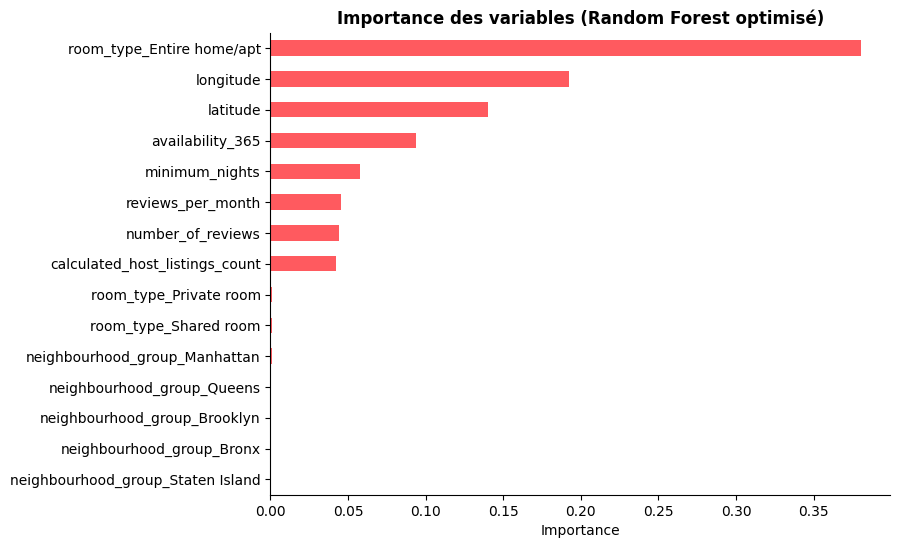

In [98]:
importances = pd.Series(modele_rf2.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
importances.plot(kind="barh", color="#FF5A5F")
plt.title("Importance des variables (Random Forest optimisé)", fontweight="bold")
plt.xlabel("Importance")
sns.despine()
plt.show()

**Interprétation :**
- Le **type de logement** est le facteur n°1 (38 %) : être un logement entier change tout.
- La **localisation** (longitude + latitude) pèse 33 %, ce qui confirme la carte des prix de l'analyse exploratoire.
- Les colonnes d'arrondissement sont presque à 0 % : les coordonnées GPS contiennent déjà cette information, de façon plus précise.

👉 Pour un investisseur, **le type de bien et l'emplacement** déterminent l'essentiel du prix.

## 8. Détecteur de bonnes affaires

On compare le **prix affiché** au **prix prédit** par le Random Forest optimisé :
**écart = prix prédit − prix affiché**. Un écart positif et élevé signale un logement **sous-évalué**.

**Choix méthodologiques :**
- On utilise le **jeu de test** : le modèle n'a jamais vu ces logements, son estimation est donc honnête.
- On garde les logements avec **au moins 10 avis**, pour écarter les annonces inactives ou peu fiables.

In [99]:
analyse = df.loc[X_test.index, ["neighbourhood_group", "neighbourhood", "room_type",
                                "price", "number_of_reviews"]].copy()

analyse["prix_predit"] = pred_rf2.round(0)
analyse["ecart"] = analyse["prix_predit"] - analyse["price"]
analyse["ecart_pct"] = (analyse["ecart"] / analyse["price"] * 100).round(1)

fiables = analyse[analyse["number_of_reviews"] >= 10]

top10 = fiables.sort_values("ecart", ascending=False).head(10)
top10

,neighbourhood_group,neighbourhood,room_type,price,number_of_reviews,prix_predit,ecart,ecart_pct
979,Manhattan,Financial District,Entire home/apt,160,36,355.0,195.0,121.9
11070,Brooklyn,Clinton Hill,Entire home/apt,105,54,300.0,195.0,185.7
28599,Manhattan,Upper East Side,Entire home/apt,140,25,332.0,192.0,137.1
36722,Manhattan,Lower East Side,Entire home/apt,59,25,250.0,191.0,323.7
1106,Manhattan,Midtown,Entire home/apt,99,30,276.0,177.0,178.8
33409,Manhattan,West Village,Entire home/apt,89,54,265.0,176.0,197.8
30927,Manhattan,West Village,Entire home/apt,125,38,301.0,176.0,140.8
31234,Manhattan,Nolita,Entire home/apt,89,15,265.0,176.0,197.8
27921,Manhattan,Midtown,Entire home/apt,130,33,290.0,160.0,123.1
19497,Brooklyn,Williamsburg,Entire home/apt,149,120,308.0,159.0,106.7


**Lecture du Top 10 :**
- Les 10 biens les plus sous-évalués sont **tous des logements entiers**, dont **8 à Manhattan** (Financial District, West Village, Midtown…) et 2 à Brooklyn.
- Ils sont affichés en moyenne à **115 \$** la nuit, alors que le modèle estime leur juste prix à **294 \$**, soit un écart moyen d'environ **+180 \$ par nuit**.

## 9. Recommandation finale

1. **Opportunités immédiates** : les 10 biens du Top 10 sont affichés bien en dessous de la valeur du marché. Acquis ou gérés par le fonds, leur prix pourrait être aligné sur l'estimation du modèle, soit un potentiel d'environ **+180 \$ par nuit**. Sur 100 nuits louées par an, cela représente environ **18 000 \$ de revenu supplémentaire par bien**.
2. **Stratégie de fond** : l'analyse exploratoire montre que les **logements entiers dans le Queens** offrent le meilleur revenu estimé sur un marché fiable.
3. **Prudence** : le modèle se trompe en moyenne de 45 \$ (MAE) et ignore des informations clés (surface, état, équipements). Un bien peut être bon marché pour une bonne raison (petite surface, travaux…). **Chaque opportunité doit être vérifiée par une visite** avant d'investir.

## 10. Sauvegarde du modèle

On **sérialise** le Random Forest optimisé avec `joblib`, au format **pickle** (`.pkl`). Sérialiser, c'est « mettre en conserve » le modèle dans un fichier : on peut ainsi le réutiliser plus tard **sans le ré-entraîner**.

On sauvegarde deux fichiers :
- `model.pkl` : le modèle entraîné.
- `colonnes.pkl` : la **liste des colonnes** utilisées à l'entraînement. Sans elle, un nouveau logement n'aurait pas les mêmes colonnes et le modèle refuserait de prédire.

On vérifie ensuite que le modèle rechargé prédit bien la même chose. On utilise `np.allclose` plutôt que `==` : les arbres étant calculés en parallèle, de minuscules différences d'arrondi (de l'ordre de 0,0000000000001 \$) peuvent apparaître, sans aucun impact sur le résultat.

In [100]:
import joblib

joblib.dump(modele_rf2, "../model.pkl", compress=3)
joblib.dump(list(X.columns), "../colonnes.pkl")

modele_charge = joblib.load("../model.pkl")
identique = np.allclose(modele_charge.predict(X_test), pred_rf2)
print("Le modèle rechargé prédit la même chose :", identique)

Le modèle rechargé prédit la même chose : True
